# Conditioning of the 2-field and 3-field matrices

The 2-norm condition number $\mathrm{cond}_2(A) = \sigma_{\max}/\sigma_{\min}$ of the matrix each model factorises once per run: the annulus with the brain parameters, P2 elements, $\Delta t$ = 10 ms. It is reported three ways:

- **raw**: $A$ as assembled, in the non-dimensional unknowns. This is what the direct solver sees.
- **Jacobi**: $|D|^{-1/2} A\,|D|^{-1/2}$, $D = \mathrm{diag}(A)$. It removes the units of each unknown.
- **Schur**: as Jacobi, but the pressure is scaled by its approximate Schur complement, i.e. by what actually controls it through the couplings. This is the scaling a block preconditioner uses.

The method is in `docs/theory.md` §10, the keys in `experiments/YAML_REFERENCE.md` §16. Mesh sizes are effective sizes, $h_{\mathrm{eff}} = (|\Omega|/N_{\mathrm{cells}})^{1/2}$.

**Geometry.** The saved results were computed on the concentric annulus (hole at the origin, radius 3 mm). The base YAMLs now have the off-centre hole, so `RERUN = True` would compute them on that geometry. The conclusions do not depend on where the hole is.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FormatStrFormatter, NullLocator
from biotx import conditioning as cn

RERUN = False                       # True: recompute every study (about 70 minutes)
NAMES = ["annulus_biot2_h", "annulus_biot3_h", "annulus_biot2_h_dt2.5ms", "annulus_biot3_h_dt2.5ms",
         "annulus_biot2_dt", "annulus_biot3_dt", "annulus_biot2_K", "annulus_biot3_K", "annulus_biot2_zeta"]
COLORS = {"biot2": "#2a78d6", "biot3": "#eb6834"}
MARKERS = {"biot2": "o", "biot3": "^"}
MODEL = {"biot2": "2F", "biot3": "3F"}
SCALING = {"raw": "raw", "jacobi": "Jacobi", "schur": "Schur"}
SC_COLORS = {"raw": "#b07d0a", "jacobi": "#7a4fc4", "schur": "#138a6a"}
SC_MARKERS = {"raw": "D", "jacobi": "s", "schur": "v"}


def get(name):
    path = Path("results") / f"{name}.npz"
    if RERUN or not path.exists():
        res = cn.run(cn.load(f"{name}.yaml"), verbose=True)
        res.save(path)
    return cn.load_result(path)


R = {n: get(n) for n in NAMES}


def scalings(r):
    return [sc for sc in SCALING if f"{sc}_cond" in r]


def x_of(r):
    # the swept quantity: h_eff in mm, dt in ms, K in m^2, zeta as is
    key = str(r["key"])
    if key.startswith("geometry"):
        return r["h_eff"] * 1e3
    return r["values"].astype(float) * (1e3 if key == "time.dt" else 1.0)


def last_slope(x, y):
    return np.log(y[-1] / y[-2]) / np.log(x[-1] / x[-2])


def style(ax, xlabel, ylabel, title, ticks, invert=True):
    if invert:
        ax.invert_xaxis()                           # refinement to the right
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(FormatStrFormatter("%.3g"))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.grid(True, which="both", color="0.9")
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.legend(frameon=False, fontsize=8.5, handlelength=3.2)

## Main result

On the experiment's mesh ($h$ = 0.5 mm, $h_{\mathrm{eff}}$ = 0.32 mm), with the growth rate in $h$ (slope of the last refinement; $-2$ is the usual rate for these discretisations):

In [2]:
rows = [["model", "dofs"] + [f"{SCALING[sc]}  (slope)" for sc in SCALING]]
for m in ("biot2", "biot3"):
    r = R[f"annulus_{m}_h"]
    x = x_of(r)
    rows.append([MODEL[m], str(int(r["dofs"][-1]))]
                + [f"{r[f'{sc}_cond'][-1]:.1e}  ({last_slope(x, r[f'{sc}_cond']):.2f})" for sc in SCALING])
w = [max(len(row[j]) for row in rows) for j in range(len(rows[0]))]
for row in rows:
    print("  " + "  ".join(c.ljust(wj) for c, wj in zip(row, w)))

  model  dofs   raw  (slope)      Jacobi  (slope)   Schur  (slope)  
  2F     49248  1.7e+06  (-1.98)  3.1e+05  (-2.06)  3.1e+05  (-2.06)
  3F     73872  5.7e+07  (-1.95)  3.1e+06  (-3.04)  1.7e+05  (-2.10)


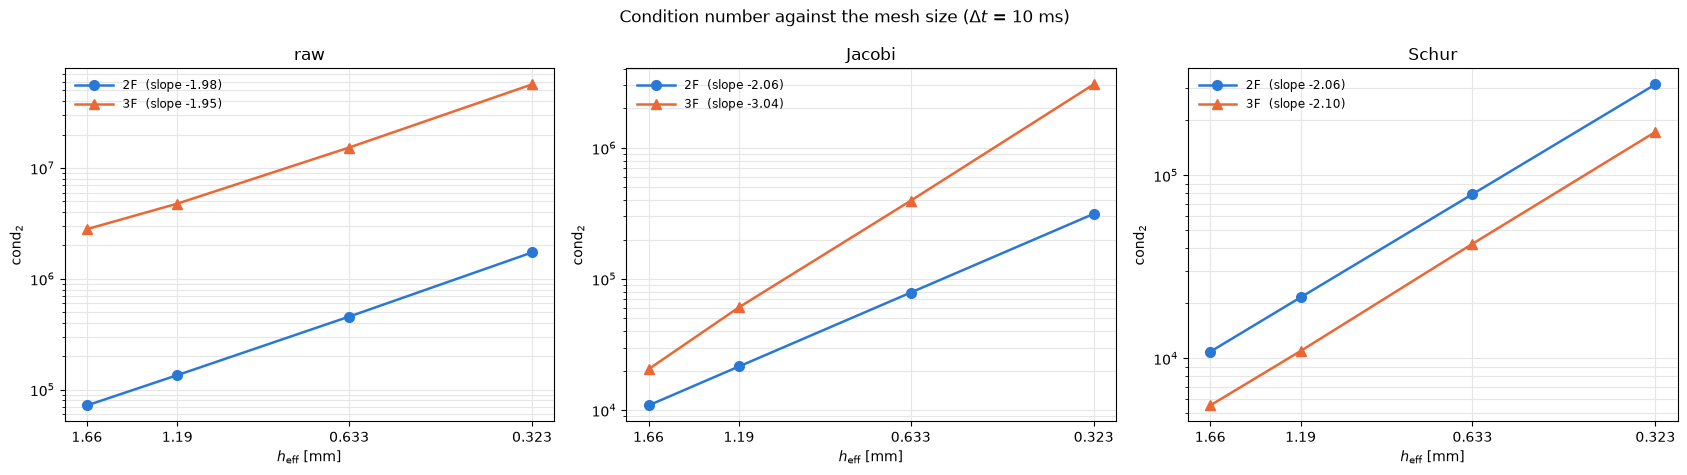

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, sc in zip(axes, SCALING):
    for m in ("biot2", "biot3"):
        r = R[f"annulus_{m}_h"]
        x, y = x_of(r), r[f"{sc}_cond"]
        ax.loglog(x, y, marker=MARKERS[m], color=COLORS[m], lw=1.8, ms=7, label=f"{MODEL[m]}  (slope {last_slope(x, y):.2f})")
    style(ax, "$h_{\\mathrm{eff}}$ [mm]", "cond$_2$", SCALING[sc], x)
fig.suptitle("Condition number against the mesh size ($\\Delta t$ = 10 ms)")
fig.tight_layout()
plt.show()

## Conclusion

- **2F** grows like $h^{-2}$ with every scaling.
- **3F raw** is 30 times worse than 2F, because of the units of its blocks: the drag term $(1/\kappa)\,w_t$ is $10^6$ times larger than the pressure storage term.
- **3F with Jacobi** grows like $h^{-3}$. Diagonal scaling under-scales the pressure, which in 3F is controlled through its coupling to $w$ (a saddle point), not by its tiny diagonal.
- **3F with Schur** grows like $h^{-2}$ again and is *lower* than 2F (0.55 times on this mesh).

**For the solver:**
- With a direct solver (MUMPS), both formulations are fine: about 8 of 16 digits remain in the worst case.
- With an iterative solver (large 3D runs), 2F works with diagonal preconditioning, while 3F needs a block preconditioner that approximates the pressure Schur complement. With it, 3F is not the harder system.

---
# Annexes

## A. Tables of every study

`slope`: rate between successive values of the swept quantity. `s_min on` / `s_max on`: the field that carries most of the singular vector of $\sigma_{\min}$ / $\sigma_{\max}$.

In [4]:
LABEL = {"time.dt": "dt [ms]", "material.K": "K [m^2]", "discretization.zeta": "zeta"}


def table(name):
    r = R[name]
    fields = [f for f in "dwp" if f"raw_share_min_{f}" in r]
    head = [LABEL.get(str(r["key"]), "h eff [mm]"), "dofs"]
    for sc in scalings(r):
        head += [f"cond {sc}", "slope", "s_min on", "s_max on"]
    rows, x = [head], x_of(r)

    def on(sc, end, i):
        share = {f: r[f"{sc}_share_{end}_{f}"][i] for f in fields}
        f = max(share, key=share.get)
        return f"{f} {share[f]:.2f}"

    for i in range(len(x)):
        row = [f"{x[i]:.3g}", str(int(r["dofs"][i]))]
        for sc in scalings(r):
            c = r[f"{sc}_cond"]
            row += [f"{c[i]:.2e}", f"{np.log(c[i] / c[i - 1]) / np.log(x[i] / x[i - 1]):.2f}" if i else "",
                    on(sc, "min", i), on(sc, "max", i)]
        rows.append(row)
    w = [max(len(row[j]) for row in rows) for j in range(len(head))]
    print(name)
    for row in rows:
        print("  " + "  ".join(c.rjust(wj) for c, wj in zip(row, w)))
    print()


for name in NAMES:
    table(name)

annulus_biot2_h
  h eff [mm]   dofs  cond raw  slope  s_min on  s_max on  cond jacobi  slope  s_min on  s_max on  cond schur  slope  s_min on  s_max on
        1.66   1872  7.20e+04           p 1.00    d 1.00     1.09e+04           p 0.99    d 1.00    1.09e+04           p 0.99    d 1.00
        1.19   3636  1.35e+05  -1.90    p 1.00    d 1.00     2.15e+04  -2.06    p 1.00    d 1.00    2.15e+04  -2.06    p 1.00    d 1.00
       0.633  12852  4.56e+05  -1.93    p 1.00    d 1.00     7.89e+04  -2.06    p 0.99    d 1.00    7.89e+04  -2.06    p 0.99    d 1.00
       0.323  49248  1.73e+06  -1.98    p 1.00    d 1.00     3.14e+05  -2.06    p 0.99    d 1.00    3.14e+05  -2.06    p 0.99    d 1.00

annulus_biot3_h
  h eff [mm]   dofs  cond raw  slope  s_min on  s_max on  cond jacobi  slope  s_min on  s_max on  cond schur  slope  s_min on  s_max on
        1.66   2808  2.80e+06           p 1.00    w 1.00     2.05e+04           d 1.00    p 0.54    5.52e+03           d 1.00    w 0.99
        1.19   

## B. Smaller time step

The same as the main figure at $\Delta t$ = 2.5 ms. The slopes are unchanged; a smaller $\Delta t$ only shifts the 3F curves.

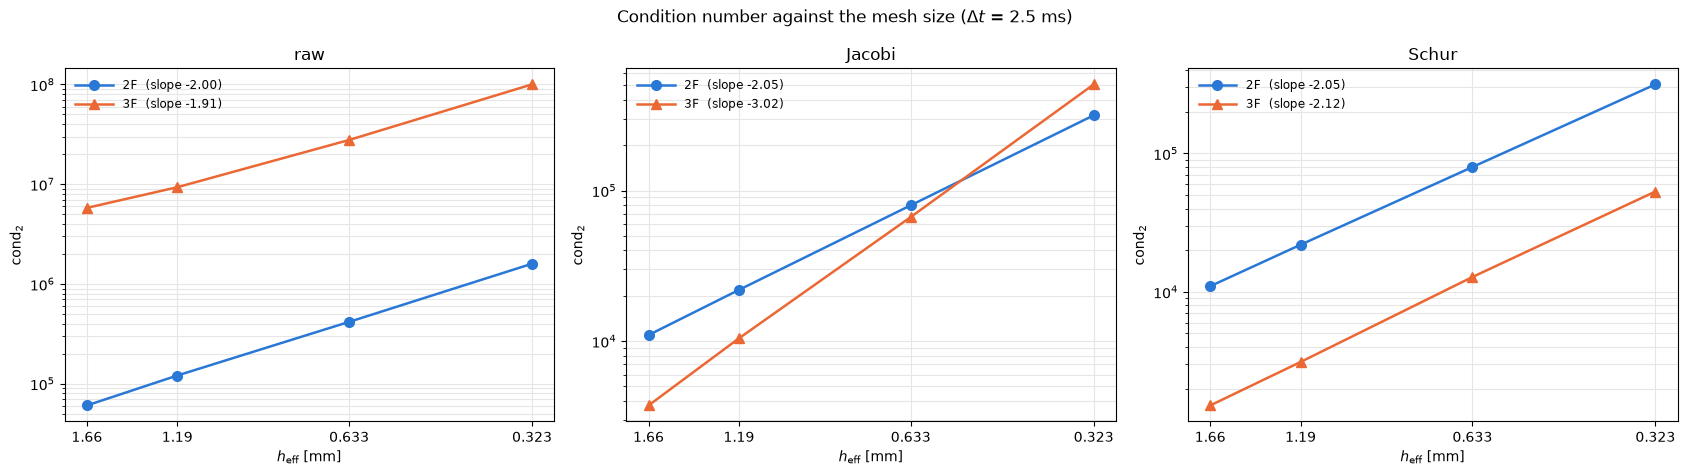

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, sc in zip(axes, SCALING):
    for m in ("biot2", "biot3"):
        r = R[f"annulus_{m}_h_dt2.5ms"]
        x, y = x_of(r), r[f"{sc}_cond"]
        ax.loglog(x, y, marker=MARKERS[m], color=COLORS[m], lw=1.8, ms=7, label=f"{MODEL[m]}  (slope {last_slope(x, y):.2f})")
    style(ax, "$h_{\\mathrm{eff}}$ [mm]", "cond$_2$", SCALING[sc], x)
fig.suptitle("Condition number against the mesh size ($\\Delta t$ = 2.5 ms)")
fig.tight_layout()
plt.show()

## C. Time step

On the experiment's mesh. 2F hardly depends on $\Delta t$. 3F raw grows as $\Delta t$ shrinks (the drag term grows like $1/\Delta t$), and 3F Jacobi decreases. These studies were run before the Schur scaling existed.

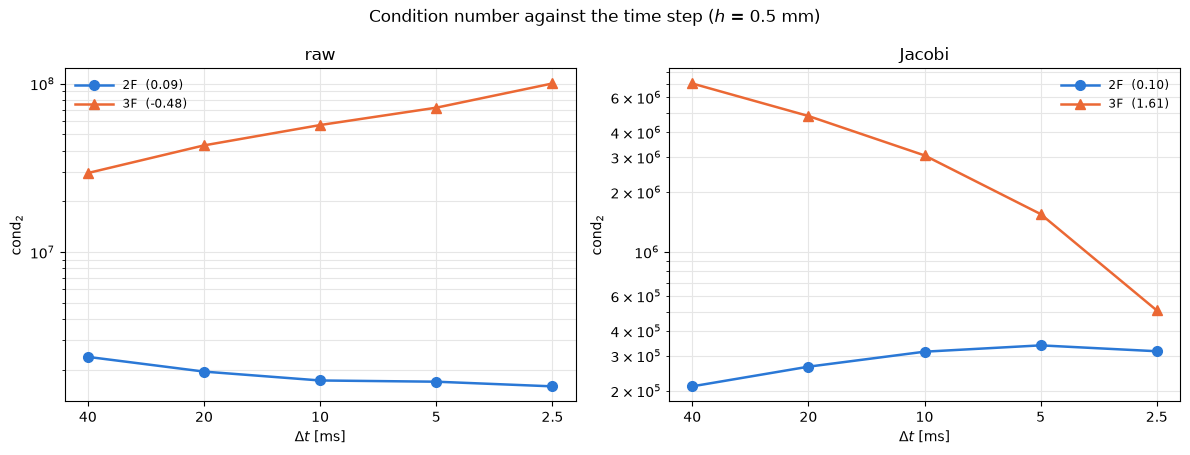

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, sc in zip(axes, ("raw", "jacobi")):
    for m in ("biot2", "biot3"):
        r = R[f"annulus_{m}_dt"]
        x, y = x_of(r), r[f"{sc}_cond"]
        ax.loglog(x, y, marker=MARKERS[m], color=COLORS[m], lw=1.8, ms=7, label=f"{MODEL[m]}  ({last_slope(x, y):.2f})")
    style(ax, "$\\Delta t$ [ms]", "cond$_2$", SCALING[sc], x)
fig.suptitle("Condition number against the time step ($h$ = 0.5 mm)")
fig.tight_layout()
plt.show()

## D. Which end of the spectrum moves

In 3F with Jacobi, $\sigma_{\max}$ grows like $h^{-1}$ while $\sigma_{\min}$ falls like $h^2$, hence $h^{-3}$. The growing $\sigma_{\max}$ is the $w$–$p$ coupling after diagonal scaling. With Schur scaling it stays bounded, and $\sigma_{\min}$ is unchanged.

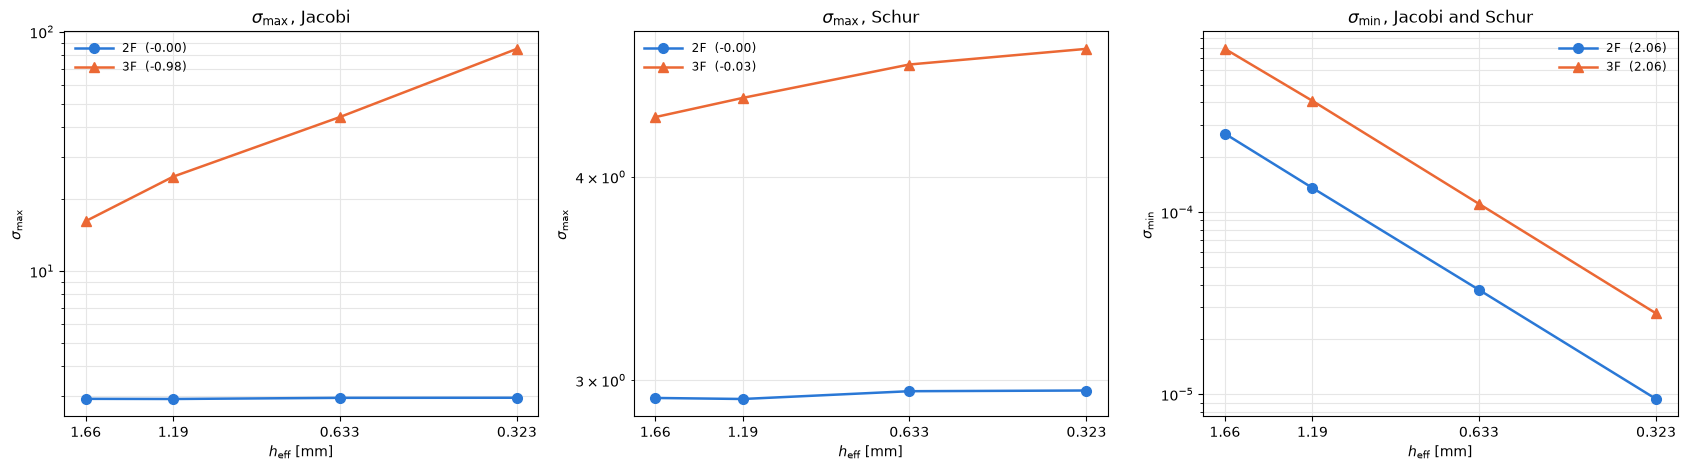

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (sc, end) in zip(axes, (("jacobi", "smax"), ("schur", "smax"), ("schur", "smin"))):
    for m in ("biot2", "biot3"):
        r = R[f"annulus_{m}_h"]
        x, y = x_of(r), r[f"{sc}_{end}"]
        ax.loglog(x, y, marker=MARKERS[m], color=COLORS[m], lw=1.8, ms=7, label=f"{MODEL[m]}  ({last_slope(x, y):.2f})")
    name = "$\\sigma_{\\max}$" if end == "smax" else "$\\sigma_{\\min}$"
    style(ax, "$h_{\\mathrm{eff}}$ [mm]", name, f"{name}, {SCALING[sc]}" if end == "smax" else f"{name}, Jacobi and Schur", x)
fig.tight_layout()
plt.show()

## E. Ratios

Left: cond(3F) / cond(2F) for each scaling (above 1: 3F is worse). Right: raw / Jacobi, the part that is only units.

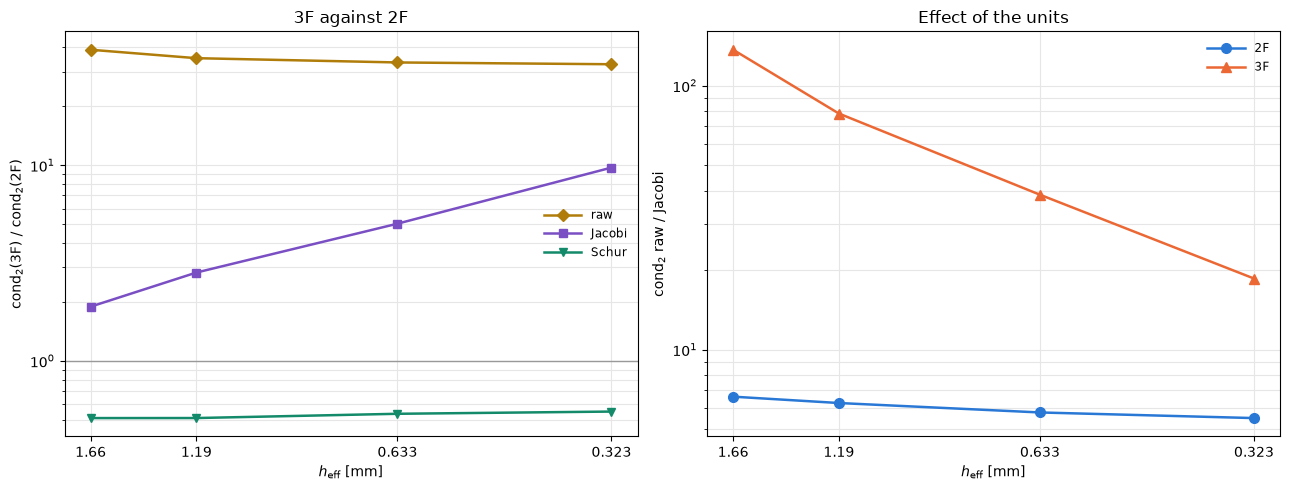

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.0))
ax = axes[0]
for sc in SCALING:
    r2, r3 = R["annulus_biot2_h"], R["annulus_biot3_h"]
    x = x_of(r2)
    ax.loglog(x, r3[f"{sc}_cond"] / r2[f"{sc}_cond"], marker=SC_MARKERS[sc], color=SC_COLORS[sc], lw=1.8, ms=6,
              label=SCALING[sc])
ax.axhline(1, color="0.6", lw=1)
style(ax, "$h_{\\mathrm{eff}}$ [mm]", "cond$_2$(3F) / cond$_2$(2F)", "3F against 2F", x)
ax = axes[1]
for m in ("biot2", "biot3"):
    r = R[f"annulus_{m}_h"]
    ax.loglog(x_of(r), r["raw_cond"] / r["jacobi_cond"], marker=MARKERS[m], color=COLORS[m], lw=1.8, ms=7, label=MODEL[m])
style(ax, "$h_{\\mathrm{eff}}$ [mm]", "cond$_2$ raw / Jacobi", "Effect of the units", x_of(r))
fig.tight_layout()
plt.show()

## F. Permeability

Two decades on each side of the brain value $1.57\cdot10^{-11}$ m² (dotted). 3F with Jacobi grows like $\sqrt K$, as the analysis of annex D predicts. 3F with Schur is nearly independent of $K$, so it is robust in $K$. 2F worsens about 5 times as $K$ decreases, then levels off.

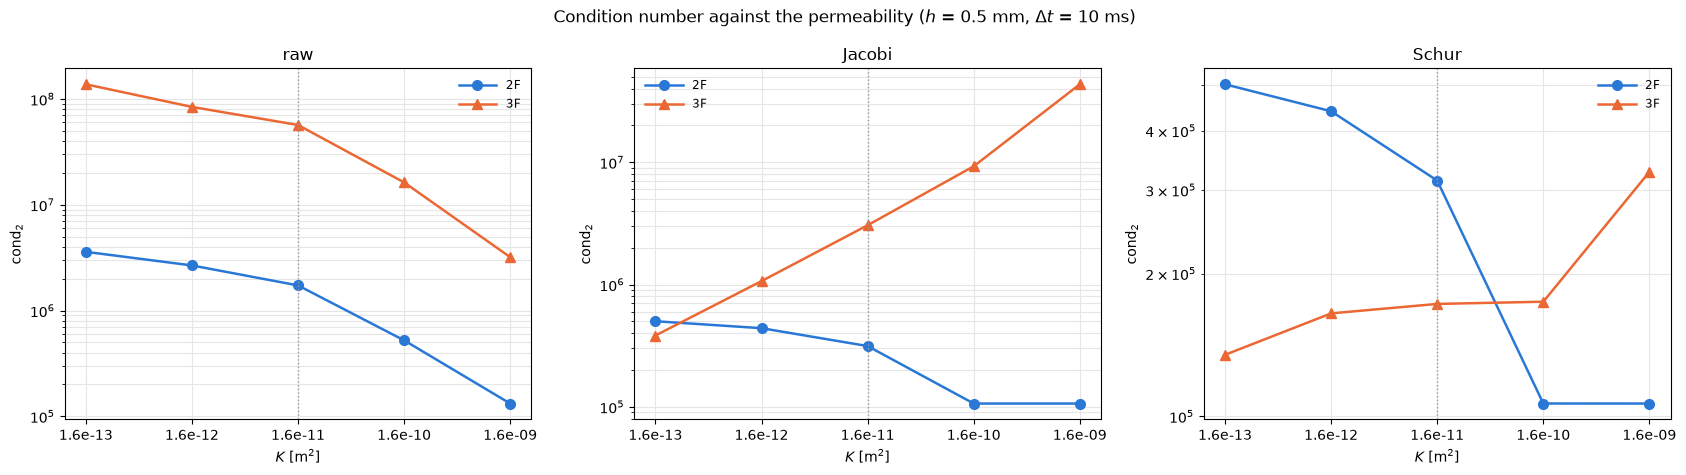

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, sc in zip(axes, SCALING):
    for m in ("biot2", "biot3"):
        r = R[f"annulus_{m}_K"]
        x, y = x_of(r), r[f"{sc}_cond"]
        ax.loglog(x, y, marker=MARKERS[m], color=COLORS[m], lw=1.8, ms=7, label=MODEL[m])
    ax.axvline(1.57e-11, color="0.6", lw=1, ls=":")
    style(ax, "$K$ [m$^2$]", "cond$_2$", SCALING[sc], x, invert=False)
    ax.xaxis.set_major_formatter(FormatStrFormatter("%.2g"))
fig.suptitle("Condition number against the permeability ($h$ = 0.5 mm, $\\Delta t$ = 10 ms)")
fig.tight_layout()
plt.show()

## G. Darcy penalty (2F)

The 2F pressure jumps are penalised by $\zeta\,\max(\kappa^*, 1)\,k^2/h_F$; default $\zeta$ = 10 (dotted). $\sigma_{\min}$ (on $p$) falls like $\zeta^{-1/2}$, so cond grows like $\sqrt\zeta$. Jacobi and Schur coincide for 2F.

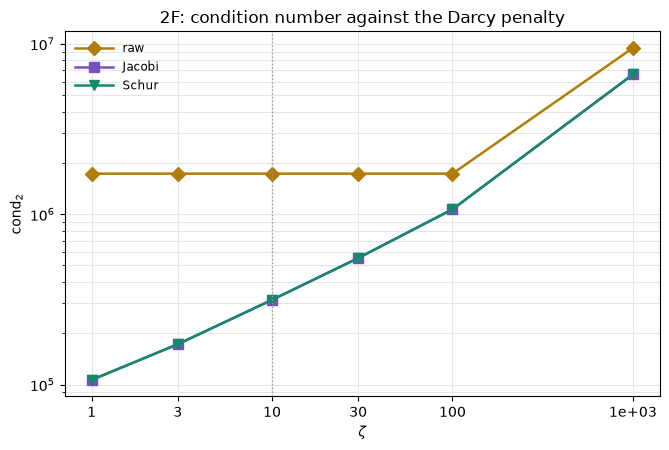

In [10]:
r = R["annulus_biot2_zeta"]
x = x_of(r)
fig, ax = plt.subplots(figsize=(6.8, 4.6))
for sc in SCALING:
    ax.loglog(x, r[f"{sc}_cond"], marker=SC_MARKERS[sc], color=SC_COLORS[sc], lw=1.8, ms=7, label=SCALING[sc])
ax.axvline(10, color="0.6", lw=1, ls=":")
style(ax, "$\\zeta$", "cond$_2$", "2F: condition number against the Darcy penalty", x, invert=False)
fig.tight_layout()
plt.show()